lag  1: retorno  0.04   retorno^2  0.09
lag  5: retorno  0.00   retorno^2  0.09
lag 10: retorno -0.00   retorno^2  0.10


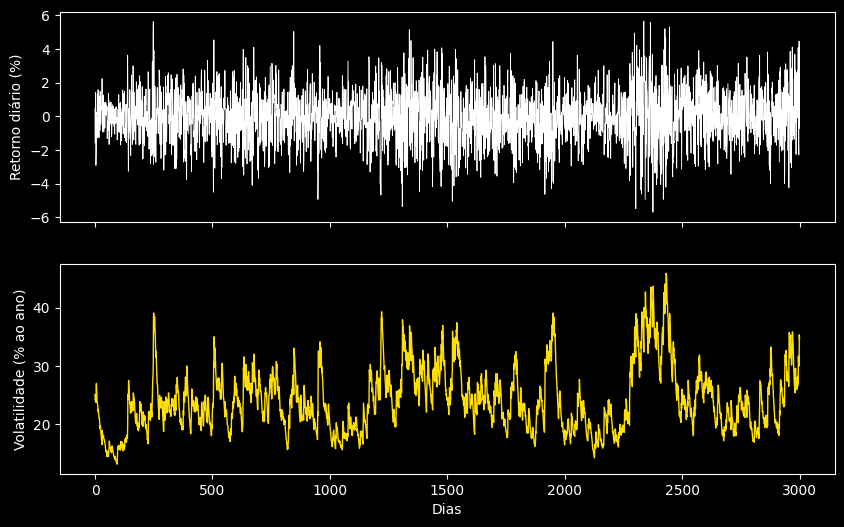

omega real  0.05  estimado  0.05
alpha real  0.08  estimado  0.07
beta  real  0.90  estimado  0.91
vol de hoje:   34.2% ao ano
vol de amanhã: 33.0% ao ano
longo prazo:   25.6% ao ano
VaR 99% de amanhã: 4.83%


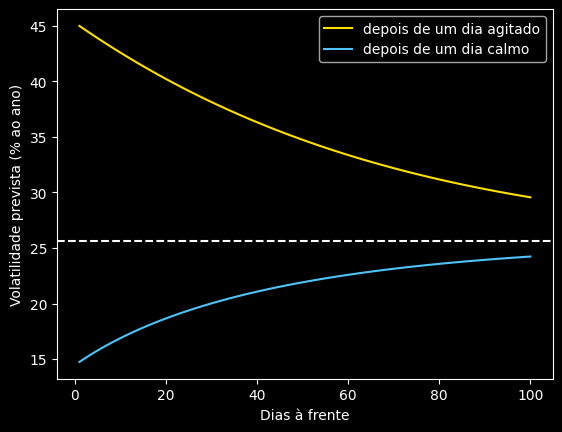

GARCH           erro  17.05  melhora   9.9%
Janela 21 dias  erro  17.33  melhora   8.4%
Constante       erro  18.92  melhora   0.0%


[*********************100%***********************]  1 of 1 completed


lag  1: retorno -0.05   retorno^2  0.25
lag  5: retorno  0.06   retorno^2  0.17
lag 10: retorno  0.02   retorno^2  0.05
alpha 0.119  beta 0.858  persistência 0.977
vol de hoje:   49.0% ao ano
vol de amanhã: 46.2% ao ano
longo prazo:   47.8% ao ano


In [1]:
#AULA 6: MODELO GARCH
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

plt.style.use("dark_background")

#Passo 1: simular um GARCH
omega, alpha, beta = 0.05, 0.08, 0.90
n = 3000
rng = np.random.default_rng(42)

s2 = np.empty(n)
r = np.empty(n)
s2[0] = omega / (1 - alpha - beta)
r[0] = np.sqrt(s2[0]) * rng.standard_normal()
for t in range(1, n):
    s2[t] = omega + alpha * r[t - 1]**2 + beta * s2[t - 1]
    r[t] = np.sqrt(s2[t]) * rng.standard_normal()

#Passo 2: a evidência dos grupos
def acf(x, k):
    x = x - x.mean()
    return (x[k:] @ x[:-k]) / (x @ x)

for k in (1, 5, 10):
    print(f"lag {k:2d}: retorno {acf(r, k):5.2f}"
          f"   retorno^2 {acf(r**2, k):5.2f}")

#Gráfico 1: retornos e volatilidade
fig, (a, b) = plt.subplots(2, 1, sharex=True,
                           figsize=(10, 6))
a.plot(r, color="white", lw=0.6)
a.set_ylabel("Retorno diário (%)")
b.plot(np.sqrt(252 * s2), color="#FFDF00", lw=1)
b.set_ylabel("Volatilidade (% ao ano)")
b.set_xlabel("Dias")
plt.show()

#Passo 3: a verossimilhança
def variancias(p, r):
    omega, alpha, beta = p
    s2 = np.empty_like(r)
    s2[0] = r.var()
    for t in range(1, len(r)):
        s2[t] = omega + alpha * r[t - 1]**2 + beta * s2[t - 1]
    return s2

def nll(p, r):
    s2 = variancias(p, r)
    return 0.5 * np.sum(np.log(s2) + r**2 / s2)

#Passo 4: ajustar
rest = {"type": "ineq", "fun": lambda p: 0.999 - p[1] - p[2]}
fit = minimize(nll, [0.1, 0.05, 0.85], args=(r,),
               method="SLSQP", constraints=[rest],
               bounds=[(1e-6, None), (0, 1), (0, 1)])
omega_h, alpha_h, beta_h = fit.x

for nome, est, real in zip(["omega", "alpha", "beta"],
                           fit.x, [omega, alpha, beta]):
    print(f"{nome:5s} real {real:5.2f}  estimado {est:5.2f}")

#Passo 5: prever amanhã
s2_h = variancias(fit.x, r)
persist = alpha_h + beta_h
lp = omega_h / (1 - persist)

s2_amanha = omega_h + alpha_h * r[-1]**2 + beta_h * s2_h[-1]
print(f"vol de hoje:   {np.sqrt(252 * s2_h[-1]):.1f}% ao ano")
print(f"vol de amanhã: {np.sqrt(252 * s2_amanha):.1f}% ao ano")
print(f"longo prazo:   {np.sqrt(252 * lp):.1f}% ao ano")
print(f"VaR 99% de amanhã: {2.326 * np.sqrt(s2_amanha):.2f}%")

#Passo 6 e Gráfico 2: a volta à médiar
h = np.arange(1, 101)
dias = {"depois de um dia agitado": s2_h.argmax(),
        "depois de um dia calmo": s2_h.argmin()}

for (nome, i), cor in zip(dias.items(), ["#FFDF00", "#4FC3F7"]):
    s2_prox = omega_h + alpha_h * r[i]**2 + beta_h * s2_h[i]
    v = lp + persist ** (h - 1) * (s2_prox - lp)
    plt.plot(h, np.sqrt(252 * v), color=cor, label=nome)

plt.axhline(np.sqrt(252 * lp), color="white", ls="--")
plt.xlabel("Dias à frente")
plt.ylabel("Volatilidade prevista (% ao ano)")
plt.legend()
plt.show()

#Passo 7: previsão fora da amostra
corte = 2000
fit2 = minimize(nll, [0.1, 0.05, 0.85], args=(r[:corte],),
                method="SLSQP", constraints=[rest],
                bounds=[(1e-6, None), (0, 1), (0, 1)])
w2, a2, b2 = fit2.x

s2_t = variancias(fit2.x, r[:corte])[-1]
prev_g, prev_h, prev_c = [], [], []
for t in range(corte - 1, n - 1):
    s2_t = w2 + a2 * r[t]**2 + b2 * s2_t
    prev_g.append(s2_t)
    prev_h.append(r[t - 20:t + 1].var())
    prev_c.append(r[:corte].var())

alvo = r[corte:]**2
erro = {nome: np.mean((alvo - np.array(p))**2)
        for nome, p in [("GARCH", prev_g),
                        ("Janela 21 dias", prev_h),
                        ("Constante", prev_c)]}

for nome, e in erro.items():
    print(f"{nome:15s} erro {e:6.2f}"
          f"  melhora {1 - e / erro['Constante']:6.1%}")

#Passo 8: dados reais (PETR4)
import pandas as pd
import yfinance as yf

px = yf.download("PETR4.SA", start="2015-01-01",
                 auto_adjust=True)["Close"].squeeze()
r_real = 100 * np.log(px / px.shift(1)).dropna().values
r_real = r_real - r_real.mean()

for k in (1, 5, 10):
    print(f"lag {k:2d}: retorno {acf(r_real, k):5.2f}"
          f"   retorno^2 {acf(r_real**2, k):5.2f}")

#Passo 9: ajustar e prever com dados reais
fit_r = minimize(nll, [0.1, 0.05, 0.85], args=(r_real,),
                 method="SLSQP", constraints=[rest],
                 bounds=[(1e-6, None), (0, 1), (0, 1)])
w, a, b = fit_r.x
s2_r = variancias(fit_r.x, r_real)
s2_prox = w + a * r_real[-1]**2 + b * s2_r[-1]
lp_r = w / (1 - a - b)

print(f"alpha {a:.3f}  beta {b:.3f}  persistência {a + b:.3f}")
print(f"vol de hoje:   {np.sqrt(252 * s2_r[-1]):.1f}% ao ano")
print(f"vol de amanhã: {np.sqrt(252 * s2_prox):.1f}% ao ano")
print(f"longo prazo:   {np.sqrt(252 * lp_r):.1f}% ao ano")